(40000, 30) (10000, 30)


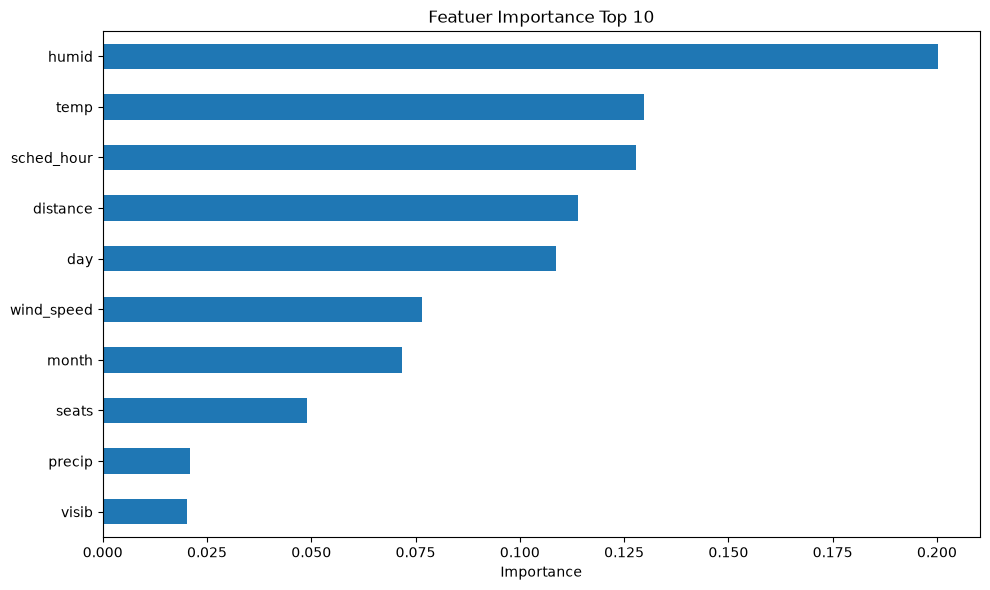

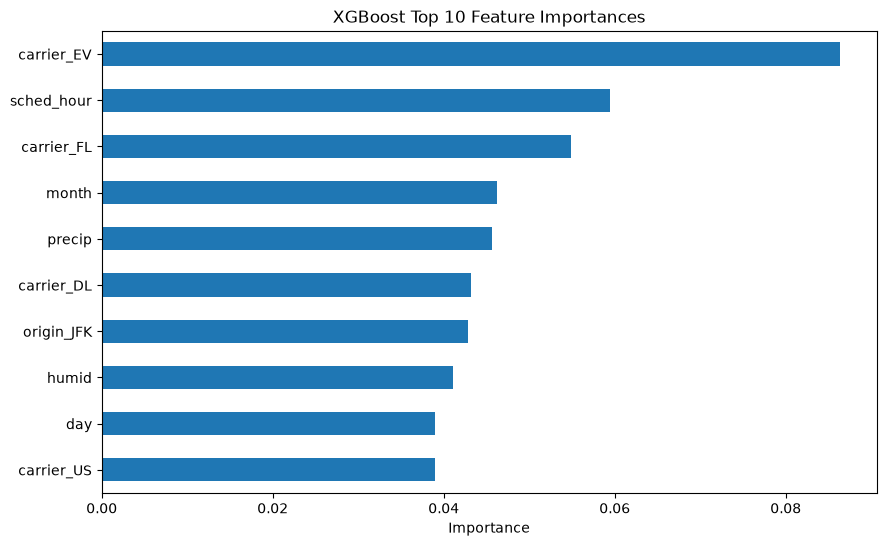

In [2]:
# 코드_공유.py
# 작업자 A, B, Admin 이 함께 사용하는 파일입니다.

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV

# 2013년 뉴욕 출발 항공편 표본 50,000건입니다.
# 항공편 정보에 기상 정보와 기체 정보를 미리 결합해 두었습니다.
df = pd.read_csv('flights_ml.csv')

NUM = ['month', 'day', 'sched_hour', 'distance', 'temp', 'humid',
       'wind_speed', 'precip', 'visib', 'seats', 'engines']
CAT = ['carrier', 'origin']

X = pd.get_dummies(df[NUM + CAT], columns=CAT)
X = X.fillna(X.median(numeric_only=True))
y = df['is_delayed']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)


####### A 작업자 작업 수행 #######
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score, accuracy_score

dt = DecisionTreeClassifier(random_state = 42)
dt_param_grid = {
    'criterion' : ['gini','entropy'],

    'max_depth' : [5,10,15],

    'min_samples_leaf' : [1,5,20]
}
dt_grid = GridSearchCV(
    estimator = dt,
    param_grid = dt_param_grid,
    cv = 5,
    scoring = 'f1',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)
best_dt = dt_grid.best_estimator_

dt_pred = best_dt.predict(X_test)
dt_f1 = f1_score(y_test, dt_pred)
dt_acc = accuracy_score(y_test, dt_pred)

dt_importances = pd.Series(best_dt.feature_importances_, index = X_train.columns)
top10_dt = dt_importances.sort_values(ascending=False).head(10)

plt.figure(figsize=(10,6))
top10_dt.sort_values().plot(kind='barh')
plt.title('Featuer Importance Top 10')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()


####### B 작업자 작업 수행 #######

from xgboost import XGBClassifier
from sklearn.metrics import f1_score, accuracy_score

xgb = XGBClassifier(random_state=42)

param_grid_xgb = {
    'max_depth': [3, 6, 9],
    'n_estimators': [100, 300],
    'learning_rate': [0.1, 0.05]
}

grid_xgb = GridSearchCV(
    estimator=xgb,
    param_grid=param_grid_xgb,
    cv=5,
    scoring='f1'
)
grid_xgb.fit(X_train, y_train)

best_xgb = grid_xgb.best_estimator_

importances_xgb = pd.Series(best_xgb.feature_importances_, index=X_train.columns)
top10_xgb = importances_xgb.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top10_xgb.sort_values().plot(kind='barh')
plt.title('XGBoost Top 10 Feature Importances')
plt.xlabel('Importance')
plt.show()

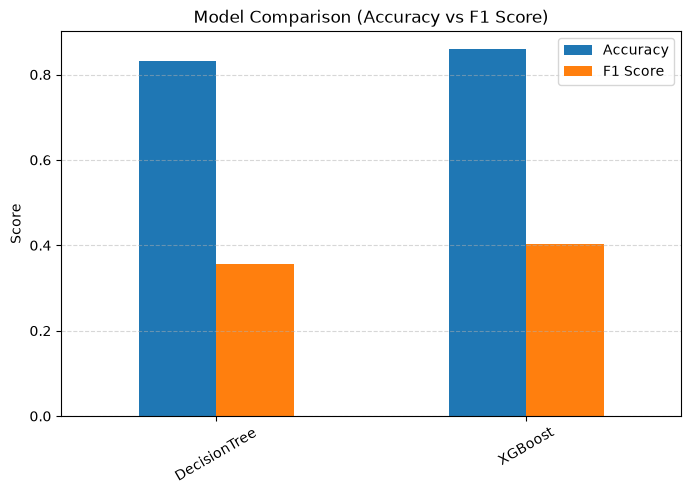

In [19]:
# Tester
y_pred_dt = best_dt.predict(X_test)
y_pred_xgb = best_xgb.predict(X_test)

results = pd.DataFrame({
    'Accuracy': [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_xgb)
    ],
    'F1 Score': [
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_xgb)
    ]
}, index=['DecisionTree', 'XGBoost'])

results.plot(kind='bar', figsize=(8, 5), rot=30)
plt.title('Model Comparison (Accuracy vs F1 Score)')
plt.ylabel('Score')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
# commit 이력 출력
import subprocess
print(subprocess.run(['git', 'log', '--oneline', '-n', '20'],
                     capture_output=True, text=True, encoding='utf-8').stdout)

c870e7b Merge pull request #2 from void-oh/B_branch
c60ab39 Merge branch 'main' into B_branch
a33dd49 Admin: DecisionTree max_depth [5,10,15]로 변경
24291f0 B: XGBoost 모델링 및 DecisionTree max_depth [3,7] 실험
25639d1 Merge pull request #1 from void-oh/A_branch
f0caa15 A: DecisionTree 모델링 및 Feature Importances 시각화
61a8e51 Admin: 작업 공간 생성

